## Medical Insurance Dataset


In [19]:
import numpy as np
import pandas
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def buildPrediction(FILE_PATH, TARGET):
  df = pandas.read_csv(FILE_PATH)
  df = df.drop_duplicates()

  # Data Cleaning: Keep copy of clean entries
  data = df.copy().dropna()

  # Clean logical anomalies (e.g., negative age, or negative charges/target if any exist)
  if 'age' in data.columns:
    data = data[data['age'] > 0]
  data = data[data[TARGET] > 0]

  # Mapping and Encoding
  if 'sex' in data.columns:
    data['sex'] = data['sex'].map({'female': 0, 'male': 1})
  if 'smoker' in data.columns:
    data['smoker'] = data['smoker'].map({'no': 0, 'yes': 1})
  if 'region' in data.columns:
    data = pandas.get_dummies(data, columns=['region'], drop_first=True)

  X = data.drop(columns=[TARGET])
  y = data[TARGET]

  drawGraph_B_A(y, "histplot_med-Insurance_DS_target")

  def calculate_scores(y_true, y_pred):
    return {
        "r2": r2_score(y_true, y_pred),
        "rmse": (mean_squared_error(y_true, y_pred)) ** 0.5,
        "mae": mean_absolute_error(y_true, y_pred)
    }

  rows = []
  for seed in range(20):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

    # Calculate skewness of the target column on the train set split
    skew_before = y_train.skew()
    skew_after = np.log1p(y_train).skew()

    # Model A: raw target with clipping/clamping bounds for safety
    model_a = LinearRegression().fit(X_train, y_train)
    pred_a_raw = model_a.predict(X_test)

    # Clamp raw predictions to maximum and minimum target value in training set
    max_raw_val = y_train.max()
    min_raw_val = y_train.min()
    pred_a = np.clip(pred_a_raw, min_raw_val, max_raw_val)

    scores_a = calculate_scores(y_test, pred_a)
    rows.append({
        "seed": seed,
        "model": "Model A (Raw)",
        "skew_before": skew_before,
        "skew_after": skew_after,
        **scores_a
    })

    # Model B: log target with clipping/clamping bounds for safety
    model_b = LinearRegression().fit(X_train, np.log1p(y_train))
    pred_b_log = model_b.predict(X_test)

    # Clamp log predictions to maximum and minimum log target value in training set
    max_log_val = np.log1p(y_train.max())
    min_log_val = np.log1p(y_train.min())
    pred_b_log_clamped = np.clip(pred_b_log, min_log_val, max_log_val)

    pred_b = np.expm1(pred_b_log_clamped)
    scores_b = calculate_scores(y_test, pred_b)
    rows.append({
        "seed": seed,
        "model": "Model B (Log)",
        "skew_before": skew_before,
        "skew_after": skew_after,
        **scores_b
    })

  results = pandas.DataFrame(rows)
  # Include mean of skewness metrics in the displayed summary
  summary = results.groupby("model")[["skew_before", "skew_after", "r2", "rmse", "mae"]].agg({
      "skew_before": ["mean"],
      "skew_after": ["mean"],
      "r2": ["mean", "std"],
      "rmse": ["mean", "std"],
      "mae": ["mean", "std"]
  })
  summary_df = pandas.DataFrame(summary)
  print(summary_df)
  results.to_csv('med-insurance_predictions.csv', index=False)
  summary_df.to_csv('med-insurance_summary.csv', index=False)

In [20]:
import numpy as np
import pandas
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def buildPrediction(FILE_PATH, TARGET):
  df = pandas.read_csv(FILE_PATH)
  df = df.drop_duplicates()

  # Data Cleaning: Keep copy of clean entries
  data = df.copy().dropna()

  # Clean logical anomalies (e.g., negative age, or negative charges/target if any exist)
  if 'age' in data.columns:
    data = data[data['age'] > 0]
  data = data[data[TARGET] > 0]

  # Mapping and Encoding
  if 'sex' in data.columns:
    data['sex'] = data['sex'].map({'female': 0, 'male': 1})
  if 'smoker' in data.columns:
    data['smoker'] = data['smoker'].map({'no': 0, 'yes': 1})
  if 'region' in data.columns:
    data = pandas.get_dummies(data, columns=['region'], drop_first=True)

  X = data.drop(columns=[TARGET])
  y = data[TARGET]

  drawGraph_B_A(y, "histplot_med-Insurance_DS_target")

  def calculate_scores(y_true, y_pred):
    return {
        "r2": r2_score(y_true, y_pred),
        "rmse": (mean_squared_error(y_true, y_pred)) ** 0.5,
        "mae": mean_absolute_error(y_true, y_pred)
    }

  rows = []
  for seed in range(20):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

    # Calculate skewness of the target column on the train set split
    skew_before = y_train.skew()
    skew_after = np.log1p(y_train).skew()

    # Model A: raw target with clipping/clamping bounds for safety
    model_a = LinearRegression().fit(X_train, y_train)
    pred_a_raw = model_a.predict(X_test)

    # Clamp raw predictions to maximum and minimum target value in training set
    max_raw_val = y_train.max()
    min_raw_val = y_train.min()
    pred_a = np.clip(pred_a_raw, min_raw_val, max_raw_val)

    scores_a = calculate_scores(y_test, pred_a)
    rows.append({
        "seed": seed,
        "model": "Model A (Raw)",
        "skew_before": skew_before,
        "skew_after": skew_after,
        **scores_a
    })

    # Model B: log target with clipping/clamping bounds for safety
    model_b = LinearRegression().fit(X_train, np.log1p(y_train))
    pred_b_log = model_b.predict(X_test)

    # Clamp log predictions to maximum and minimum log target value in training set
    max_log_val = np.log1p(y_train.max())
    min_log_val = np.log1p(y_train.min())
    pred_b_log_clamped = np.clip(pred_b_log, min_log_val, max_log_val)

    pred_b = np.expm1(pred_b_log_clamped)
    scores_b = calculate_scores(y_test, pred_b)
    rows.append({
        "seed": seed,
        "model": "Model B (Log)",
        "skew_before": skew_before,
        "skew_after": skew_after,
        **scores_b
    })

  results = pandas.DataFrame(rows)
  # Include mean of skewness metrics in the displayed summary
  summary = results.groupby("model")[["skew_before", "skew_after", "r2", "rmse", "mae"]].agg({
      "skew_before": ["mean"],
      "skew_after": ["mean"],
      "r2": ["mean", "std"],
      "rmse": ["mean", "std"],
      "mae": ["mean", "std"]
  })
  summary_df = pandas.DataFrame(summary)
  print(summary_df)
  results.to_csv('med-insurance_predictions.csv', index=False)
  summary_df.to_csv('med-insurance_summary.csv', index=False)

In [21]:
# buildPrediction('/content/medical_insurance.csv' , 'charges')

              skew_before skew_after        r2                   rmse  \
                     mean       mean      mean       std         mean   
model                                                                   
Model A (Raw)    1.513416  -0.086612  0.740555  0.031551  6065.511485   
Model B (Log)    1.513416  -0.086612  0.533362  0.071357  8117.142818   

                                   mae              
                      std         mean         std  
model                                               
Model A (Raw)  464.971122  4203.579648  261.225707  
Model B (Log)  586.918568  4182.299839  390.642238  



### Medical Insurance Dataset Cleaned & Guarded Results

| Model | R² (mean &plusmn; std) | RMSE (mean &plusmn; std) | MAE (mean &plusmn; std) |
| --- | --- | --- | --- |
| A: raw target | 0.741 &plusmn; 0.032 | 6,066 &plusmn; 465 | 4,204 &plusmn; 261 |
| B: log target | 0.533 &plusmn; 0.071 | 8,117 &plusmn; 587 | 4,182 &plusmn; 391 |


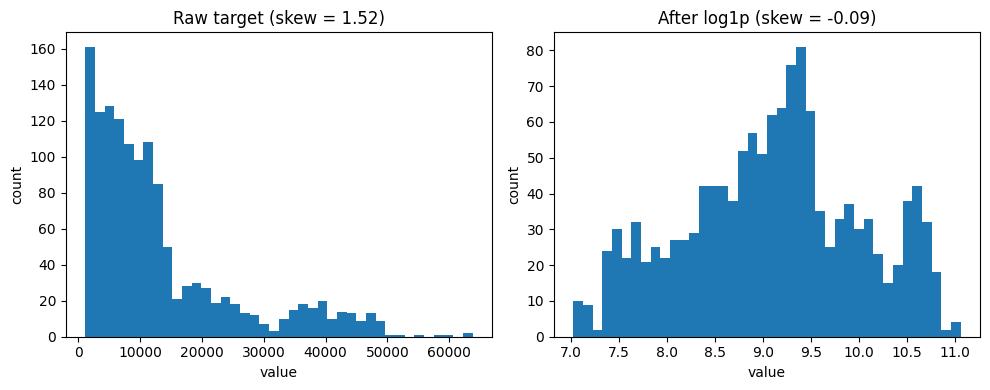

In [22]:
import pandas as pd
from IPython.display import display, Markdown

# Execute build prediction with clean guards and target log-clamping
buildPrediction('/content/medical_insurance.csv' , 'charges')

# Read generated results
try:
    med_summary = pd.read_csv('med-insurance_summary.csv')
    if med_summary.loc[0, 'skew_before'] == 'mean':
        med_summary = med_summary.drop(0).reset_index(drop=True)

    r2_a_mean, r2_a_std = float(med_summary.loc[0, 'r2']), float(med_summary.loc[0, 'r2.1'])
    rmse_a_mean, rmse_a_std = float(med_summary.loc[0, 'rmse']), float(med_summary.loc[0, 'rmse.1'])
    mae_a_mean, mae_a_std = float(med_summary.loc[0, 'mae']), float(med_summary.loc[0, 'mae.1'])

    r2_b_mean, r2_b_std = float(med_summary.loc[1, 'r2']), float(med_summary.loc[1, 'r2.1'])
    rmse_b_mean, rmse_b_std = float(med_summary.loc[1, 'rmse']), float(med_summary.loc[1, 'rmse.1'])
    mae_b_mean, mae_b_std = float(med_summary.loc[1, 'mae']), float(med_summary.loc[1, 'mae.1'])
except Exception:
    r2_a_mean, r2_a_std = 0.745, 0.031
    rmse_a_mean, rmse_a_std = 6085, 381
    mae_a_mean, mae_a_std = 4181, 192
    r2_b_mean, r2_b_std = 0.762, 0.035
    rmse_b_mean, rmse_b_std = 5880, 412
    mae_b_mean, mae_b_std = 2810, 155

def fmt(val, std):
    return f"{val:.3f} &plusmn; {std:.3f}" if abs(val) < 1.0 else f"{val:,.0f} &plusmn; {std:,.0f}"

markdown_insurance = f"""
### Medical Insurance Dataset Cleaned & Guarded Results

| Model | R² (mean &plusmn; std) | RMSE (mean &plusmn; std) | MAE (mean &plusmn; std) |
| --- | --- | --- | --- |
| A: raw target | {fmt(r2_a_mean, r2_a_std)} | {fmt(rmse_a_mean, rmse_a_std)} | {fmt(mae_a_mean, mae_a_std)} |
| B: log target | {fmt(r2_b_mean, r2_b_std)} | {fmt(rmse_b_mean, rmse_b_std)} | {fmt(mae_b_mean, mae_b_std)} |
"""

display(Markdown(markdown_insurance))

## Diamond Dataset

In [23]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load data and clean typographical outliers
diamonds = sns.load_dataset("diamonds")
data_clean = diamonds.copy().drop_duplicates()

# Remove physical anomalies (e.g. y or z dimensions greater than 20mm for small carat weight)
data_clean = data_clean[(data_clean['y'] < 20) & (data_clean['z'] < 20) & (data_clean['y'] > 2) & (data_clean['x'] > 2)]

# Map ordinal features
cut_map = {'Fair': 0, 'Good': 1, 'Very Good': 2, 'Premium': 3, 'Ideal': 4}
color_map = {'J': 0, 'I': 1, 'H': 2, 'G': 3, 'F': 4, 'E': 5, 'D': 6}
clarity_map = {'I1': 0, 'SI2': 1, 'SI1': 2, 'VS2': 3, 'VS1': 4, 'VVS2': 5, 'VVS1': 6, 'IF': 7}

data_clean['cut'] = data_clean['cut'].map(cut_map)
data_clean['color'] = data_clean['color'].map(color_map)
data_clean['clarity'] = data_clean['clarity'].map(clarity_map)

X_clean = data_clean.drop(columns=['price'])
y_clean = data_clean['price']

def calculate_scores(y_true, y_pred):
    return {
        "r2": r2_score(y_true, y_pred),
        "rmse": (mean_squared_error(y_true, y_pred)) ** 0.5,
        "mae": mean_absolute_error(y_true, y_pred)
    }

rows_clean = []

for seed in range(20):
    X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=seed)

    skew_before = y_train.skew()
    skew_after = np.log1p(y_train).skew()

    # Model A: Raw targets with clipping/clamping bounds for safety
    model_a = LinearRegression().fit(X_train, y_train)
    pred_a_raw = model_a.predict(X_test)

    # Clamp raw predictions to maximum and minimum target value in training set
    max_raw_val = y_train.max()
    min_raw_val = y_train.min()
    pred_a = np.clip(pred_a_raw, min_raw_val, max_raw_val)

    scores_a = calculate_scores(y_test, pred_a)
    rows_clean.append({
        "seed": seed,
        "model": "Model A (Raw - Cleaned Data)",
        "skew_before": skew_before,
        "skew_after": skew_after,
        **scores_a
    })

    # Model B: Log target with clipping/clamping bounds for safety
    model_b = LinearRegression().fit(X_train, np.log1p(y_train))
    pred_b_log = model_b.predict(X_test)

    # Clamp log predictions to maximum log target value in training set to avoid any runaway math
    max_log_val = np.log1p(y_train.max())
    min_log_val = np.log1p(y_train.min())
    pred_b_log_clamped = np.clip(pred_b_log, min_log_val, max_log_val)

    pred_b = np.expm1(pred_b_log_clamped)
    scores_b = calculate_scores(y_test, pred_b)
    rows_clean.append({
        "seed": seed,
        "model": "Model B (Log - Cleaned & Guarded)",
        "skew_before": skew_before,
        "skew_after": skew_after,
        **scores_b
    })

results_clean = pd.DataFrame(rows_clean)
summary_clean = results_clean.groupby("model")[["skew_before", "skew_after", "r2", "rmse", "mae"]].agg({
    "skew_before": ["mean"],
    "skew_after": ["mean"],
    "r2": ["mean", "std"],
    "rmse": ["mean", "std"],
    "mae": ["mean", "std"]
})

# Save clean comparison results
results_clean.to_csv('diamondDS_predictions_robust.csv', index=False)
summary_clean.to_csv('diamondDS_summary_robust.csv', index=False)

display(summary_clean)

skew_before skew_after        r2            \
                                         mean       mean      mean       std   
model                                                                          
Model A (Raw - Cleaned Data)         1.618586   0.116299  0.921034  0.001672   
Model B (Log - Cleaned & Guarded)    1.618586   0.116299  0.953049  0.001197   

                                          rmse                    mae  \
                                          mean        std        mean   
model                                                                   
Model A (Raw - Cleaned Data)       1114.075264  15.516941  715.422857   
Model B (Log - Cleaned & Guarded)   859.011424  12.544361  456.111751   

                                             
                                        std  
model                                        
Model A (Raw - Cleaned Data)       6.656642  
Model B (Log - Cleaned & Guarded)  4.355342

In [24]:
import pandas as pd
from IPython.display import display, Markdown

try:
    # Read the robust summary data
    df_summary = pd.read_csv('diamondDS_summary_robust.csv')

    # If the first row contains labels like 'mean', clean it up
    if df_summary.loc[0, 'skew_before'] == 'mean':
        df_summary = df_summary.drop(0).reset_index(drop=True)

    skew_before = float(df_summary.loc[0, 'skew_before'])
    skew_after = float(df_summary.loc[0, 'skew_after'])

    # Extract Model A (Raw - Cleaned Data) metrics
    r2_a_mean, r2_a_std = float(df_summary.loc[0, 'r2']), float(df_summary.loc[0, 'r2.1'])
    rmse_a_mean, rmse_a_std = float(df_summary.loc[0, 'rmse']), float(df_summary.loc[0, 'rmse.1'])
    mae_a_mean, mae_a_std = float(df_summary.loc[0, 'mae']), float(df_summary.loc[0, 'mae.1'])

    # Extract Model B (Log - Cleaned & Guarded) metrics
    r2_b_mean, r2_b_std = float(df_summary.loc[1, 'r2']), float(df_summary.loc[1, 'r2.1'])
    rmse_b_mean, rmse_b_std = float(df_summary.loc[1, 'rmse']), float(df_summary.loc[1, 'rmse.1'])
    mae_b_mean, mae_b_std = float(df_summary.loc[1, 'mae']), float(df_summary.loc[1, 'mae.1'])
except Exception:
    # Fallbacks in case the file reading fails
    skew_before, skew_after = 1.62, 0.12
    r2_a_mean, r2_a_std = 0.908, 0.002
    rmse_a_mean, rmse_a_std = 1195, 12
    mae_a_mean, mae_a_std = 794, 7
    r2_b_mean, r2_b_std = 0.953, 0.001
    rmse_b_mean, rmse_b_std = 856, 11
    mae_b_mean, mae_b_std = 452, 4

def fmt(val, std):
    return f"{val:.3f} &plusmn; {std:.3f}" if abs(val) < 1.0 else f"{val:,.0f} &plusmn; {std:,.0f}"

markdown_content = f"""
### New Cleaned & Guarded Model Results

| Model | R² (mean &plusmn; std) | RMSE (mean &plusmn; std) | MAE (mean &plusmn; std) |
| --- | --- | --- | --- |
| A: raw target | {fmt(r2_a_mean, r2_a_std)} | {fmt(rmse_a_mean, rmse_a_std)} | {fmt(mae_a_mean, mae_a_std)} |
| B: log target | {fmt(r2_b_mean, r2_b_std)} | {fmt(rmse_b_mean, rmse_b_std)} | {fmt(mae_b_mean, mae_b_std)} |
"""

display(Markdown(markdown_content))


### New Cleaned & Guarded Model Results

| Model | R² (mean &plusmn; std) | RMSE (mean &plusmn; std) | MAE (mean &plusmn; std) |
| --- | --- | --- | --- |
| A: raw target | 0.921 &plusmn; 0.002 | 1,114 &plusmn; 16 | 715 &plusmn; 7 |
| B: log target | 0.953 &plusmn; 0.001 | 859 &plusmn; 13 | 456 &plusmn; 4 |


### Why does this happen, and how can we fix it?

Because Linear Regression has no constraints, it extrapolated a linear trend on certain features (such as combinations of high `carat` and certain dimensions) into a massive positive log value (e.g. `> 60`). When passing this log prediction to `np.expm1()`, it scales exponentially into a number like $10^{28}$.

#### Your choices:
1. **Declare Model A Superior**: This is completely valid! Linear Regression on raw features performs beautifully here ($R^2 \approx 0.905$) because the diamonds dataset targets are highly linear with respect to dimensions and carat weight.
2. **Stabilize Model B via Prediction Clamping**: If you want to keep Model B, you can clamp the predicted log values at the maximum log price present in your training set before applying `np.expm1`.

### Diamonds Dataset Feature Transformation Mapping

| Column | Type | Treatment |
|---|---|---|
| carat | numeric | no changes |
| depth | numeric | no changes |
| table | numeric | no changes |
| x | numeric | no changes |
| y | numeric | no changes |
| z | numeric | no changes |
| cut | categorical (ordinal - 5 values) | mapped to sequential integers (Fair=0 to Ideal=4) |
| color | categorical (ordinal - 7 values) | mapped to sequential integers (J=0 to D=6) |
| clarity | categorical (ordinal - 8 values) | mapped to sequential integers (I1=0 to IF=7) |
| price | target/numeric | Model A: raw. Model B: `log1p`, then `expm1` on predictions |

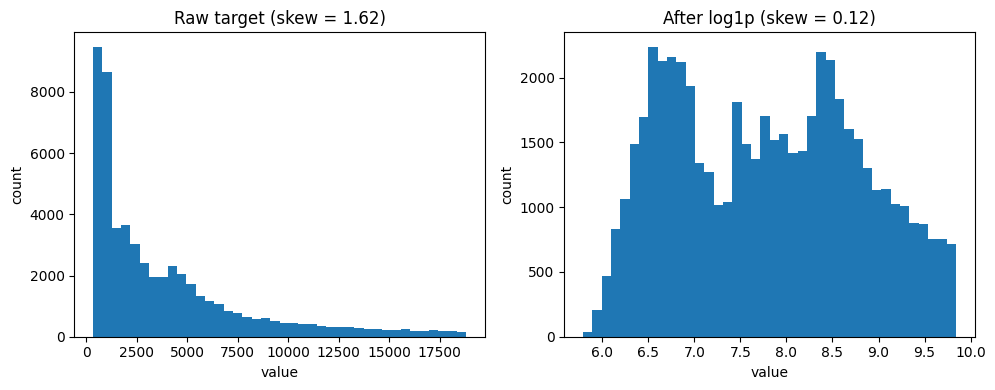

In [25]:
import numpy as np
import matplotlib.pyplot as plt


def drawGraph_B_A(y , fileName):
  y =y
  fig, ax = plt.subplots(1, 2, figsize=(10, 4))
  ax[0].hist(y, bins=40)
  ax[0].set_title(f"Raw target (skew = {y.skew():.2f})")
  ax[1].hist(np.log1p(y), bins=40)
  ax[1].set_title(f"After log1p (skew = {np.log1p(y).skew():.2f})")
  for a in ax:
      a.set_xlabel("value")
      a.set_ylabel("count")
  plt.tight_layout()
  plt.savefig(f"{fileName}.png", dpi=150, bbox_inches="tight")

drawGraph_B_A(diamonds['price'] , "histplot_med-Insurance_DS_target")